<a href="https://colab.research.google.com/github/mmkinfo25-prog/python/blob/main/notebook53a086c44c.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
ngawangchoeda_car_price_dataset_path = kagglehub.dataset_download('ngawangchoeda/car-price-dataset')
yasserh_student_marks_dataset_path = kagglehub.dataset_download('yasserh/student-marks-dataset')

print('Data source import complete.')


In [ ]:
print("Welcome to KITE")

a = 10
b = 20
print(a + b)

Welcome to KITE
30


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import glob
import os

files = glob.glob('/kaggle/input/**/*.csv', recursive=True)

print("Available CSV files:")
for file in files:
    print(file)

csv_files = [
    f for f in files
    if 'student' in os.path.basename(f).lower()
    and 'mark' in os.path.basename(f).lower()
]

if not csv_files:
    raise FileNotFoundError(
        "Student Marks CSV not found. Check the Kaggle Input panel."
    )

df = pd.read_csv(csv_files[0])

print("\nDataset loaded successfully!")
print("Selected file:", csv_files[0])

df.head()

Available CSV files:
/kaggle/input/datasets/yasserh/student-marks-dataset/Student_Marks.csv
/kaggle/input/datasets/ngawangchoeda/car-price-dataset/CarPrice.csv

Dataset loaded successfully!
Selected file: /kaggle/input/datasets/yasserh/student-marks-dataset/Student_Marks.csv


,number_courses,time_study,Marks
0,3,4.508,19.202
1,4,0.096,7.734
2,4,3.133,13.811
3,6,7.909,53.018
4,8,7.811,55.299


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
display(df.describe(include='all'))

print("\nFirst 5 Records:")
display(df.head())

print("\nLast 5 Records:")
display(df.tail())

Dataset Shape: (100, 3)

Column Names:
['number_courses', 'time_study', 'Marks']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   number_courses  100 non-null    int64  
 1   time_study      100 non-null    float64
 2   Marks           100 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 2.5 KB

Statistical Description:


,number_courses,time_study,Marks
count,100.000000,100.000000,100.000000
mean,5.290000,4.077140,24.417690
std,1.799523,2.372914,14.326199
min,3.000000,0.096000,5.609000
25%,4.000000,2.058500,12.633000
50%,5.000000,4.022000,20.059500
75%,7.000000,6.179250,36.676250
max,8.000000,7.957000,55.299000



First 5 Records:


,number_courses,time_study,Marks
0,3,4.508,19.202
1,4,0.096,7.734
2,4,3.133,13.811
3,6,7.909,53.018
4,8,7.811,55.299



Last 5 Records:


,number_courses,time_study,Marks
95,6,3.561,19.128
96,3,0.301,5.609
97,4,7.163,41.444
98,7,0.309,12.027
99,3,6.335,32.357


In [ ]:

print("Missing Values:")
print(df.isnull().sum())


print("\nDuplicate Records:", df.duplicated().sum())


df = df.drop_duplicates().reset_index(drop=True)


print("\nAfter Cleaning:", df.shape)


print("\nData Types:")
print(df.dtypes)


print("\nNumerical Features:")
print(df.select_dtypes(include=np.number).columns.tolist())

Missing Values:
number_courses    0
time_study        0
Marks             0
dtype: int64

Duplicate Records: 0

After Cleaning: (100, 3)

Data Types:
number_courses      int64
time_study        float64
Marks             float64
dtype: object

Numerical Features:
['number_courses', 'time_study', 'Marks']


In [ ]:

target_candidates = [
    col for col in df.columns
    if col.strip().lower() == 'marks'
]

if not target_candidates:
    raise ValueError(
        f"Target column 'Marks' not found. Available columns: {df.columns.tolist()}"
    )

target = target_candidates[0]


X = df.drop(columns=[target])
y = df[target]

print("Input Features:")
print(X.columns.tolist())

print("\nTarget Variable:", target)

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

Input Features:
['number_courses', 'time_study']

Target Variable: Marks

X Shape: (100, 2)
y Shape: (100,)


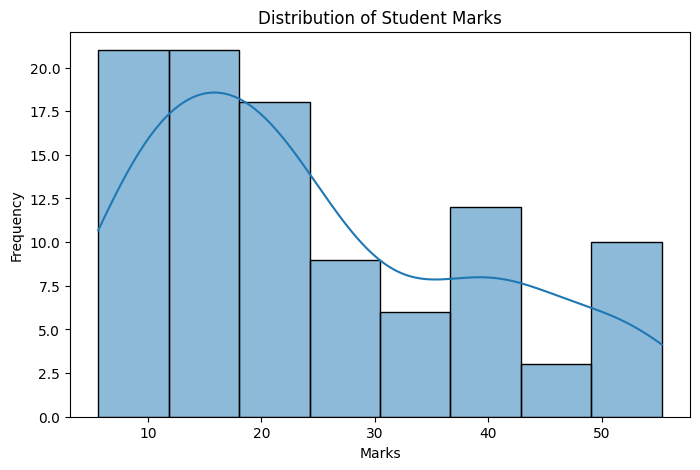

In [ ]:

plt.figure(figsize=(8, 5))

sns.histplot(y, kde=True)

plt.title("Distribution of Student Marks")
plt.xlabel("Marks")
plt.ylabel("Frequency")

plt.show()

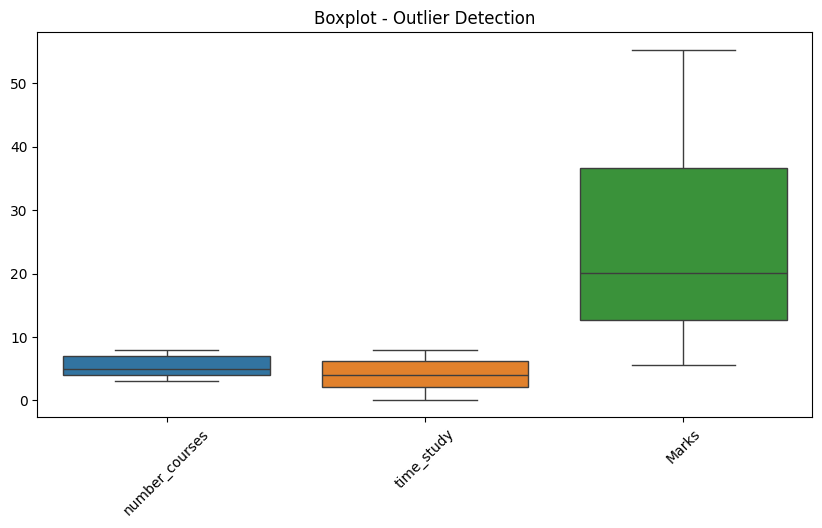

In [ ]:

num_cols = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(10, 5))

sns.boxplot(data=df[num_cols])

plt.title("Boxplot - Outlier Detection")
plt.xticks(rotation=45)

plt.show()

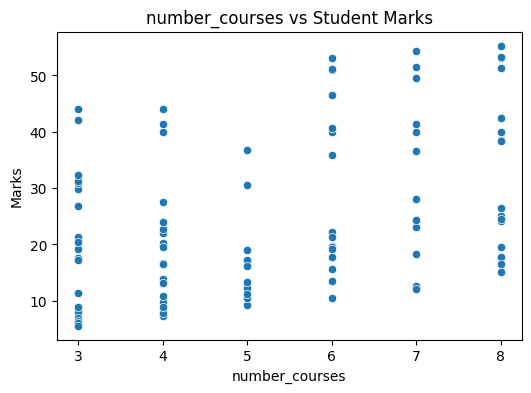

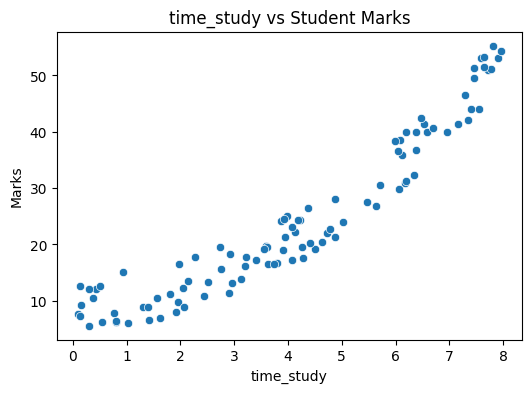

In [ ]:
feature_cols = X.select_dtypes(include=np.number).columns

for col in feature_cols:

    plt.figure(figsize=(6, 4))

    sns.scatterplot(x=df[col], y=y)

    plt.title(f"{col} vs Student Marks")
    plt.xlabel(col)
    plt.ylabel("Marks")

    plt.show()

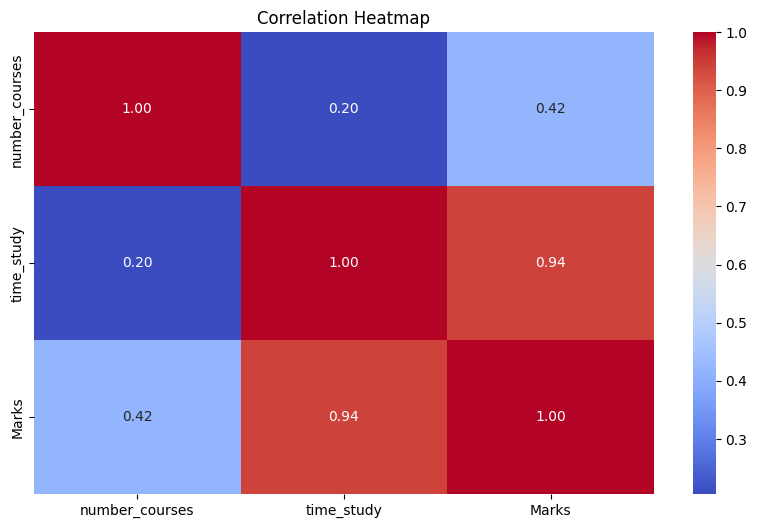

In [ ]:
plt.figure(figsize=(10, 6))

corr = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (80, 2)
Testing Data: (20, 2)


In [ ]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing completed.")

Preprocessing completed.


 Identify target column irrespective of letter case

In [ ]:
models = {

    "Linear Regression":
        LinearRegression(),

    "Ridge Regression":
        Ridge(alpha=1.0),

    "Decision Tree":
        DecisionTreeRegressor(
            max_depth=4,
            random_state=42
        ),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=100,
            max_depth=5,
            random_state=42
        ),

    "Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=2,
            random_state=42
        ),

    "Support Vector Regression":
        SVR(
            kernel='rbf',
            C=10,
            epsilon=0.1
        )
}


In [ ]:
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} trained successfully!")

Linear Regression trained successfully!
Ridge Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!
Support Vector Regression trained successfully!


In [ ]:
results = []

for name, model in trained_models.items():


    y_pred = model.predict(X_test)


    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)


    n = len(y_test)
    p = X_test.shape[1]

    if n > p + 1:
        adj_r2 = 1 - (
            (1 - r2) * (n - 1) / (n - p - 1)
        )
    else:
        adj_r2 = np.nan


    nonzero_mask = np.asarray(y_test) != 0

    if nonzero_mask.any():
        mape = np.mean(
            np.abs(
                (np.asarray(y_test)[nonzero_mask] -
                 y_pred[nonzero_mask]) /
                np.asarray(y_test)[nonzero_mask]
            )
        ) * 100
    else:
        mape = np.nan


    cv_scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring='r2'
    )

    cv_r2 = cv_scores.mean()

    results.append({

        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2,
        'Adjusted R2': adj_r2,
        'MAPE (%)': mape,
        'CV R2': cv_r2

    })

    print(f"\n{name}")
    print("-----------------------------")
    print("MAE:", round(mae, 4))
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("R2 Score:", round(r2, 4))
    print("Adjusted R2:", round(adj_r2, 4)
          if not np.isnan(adj_r2) else "Not available")
    print("MAPE (%):", round(mape, 2)
          if not np.isnan(mape) else "Not available")
    print("Cross Validation R2:", round(cv_r2, 4))


Linear Regression
-----------------------------
MAE: 3.0793
MSE: 14.2007
RMSE: 3.7684
R2 Score: 0.946
Adjusted R2: 0.9396
MAPE (%): 11.28
Cross Validation R2: 0.9325

Ridge Regression
-----------------------------
MAE: 3.1753
MSE: 15.0519
RMSE: 3.8797
R2 Score: 0.9428
Adjusted R2: 0.936
MAPE (%): 11.81
Cross Validation R2: 0.9326

Decision Tree
-----------------------------
MAE: 1.9232
MSE: 5.704
RMSE: 2.3883
R2 Score: 0.9783
Adjusted R2: 0.9758
MAPE (%): 13.11
Cross Validation R2: 0.9621

Random Forest
-----------------------------
MAE: 1.3439
MSE: 2.331
RMSE: 1.5268
R2 Score: 0.9911
Adjusted R2: 0.9901
MAPE (%): 6.92
Cross Validation R2: 0.9827

Gradient Boosting
-----------------------------
MAE: 1.4695
MSE: 3.3979
RMSE: 1.8433
R2 Score: 0.9871
Adjusted R2: 0.9856
MAPE (%): 7.08
Cross Validation R2: 0.9873

Support Vector Regression
-----------------------------
MAE: 0.831
MSE: 1.8807
RMSE: 1.3714
R2 Score: 0.9928
Adjusted R2: 0.992
MAPE (%): 2.49
Cross Validation R2: 0.9947


In [ ]:
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by='R2 Score',
    ascending=False
).reset_index(drop=True)

print("MACHINE LEARNING MODEL COMPARISON")

display(
    comparison_df.style
    .format({
        'MAE': '{:.4f}',
        'MSE': '{:.4f}',
        'RMSE': '{:.4f}',
        'R2 Score': '{:.4f}',
        'Adjusted R2': '{:.4f}',
        'MAPE (%)': '{:.2f}',
        'CV R2': '{:.4f}'
    })
    .highlight_max(
        subset=['R2 Score', 'Adjusted R2', 'CV R2'],
        color='lightgreen'
    )
    .highlight_min(
        subset=['MAE', 'MSE', 'RMSE', 'MAPE (%)'],
        color='lightgreen'
    )
)

MACHINE LEARNING MODEL COMPARISON


,Model,MAE,MSE,RMSE,R2 Score,Adjusted R2,MAPE (%),CV R2
0,Support Vector Regression,0.8310,1.8807,1.3714,0.9928,0.9920,2.49,0.9947
1,Random Forest,1.3439,2.3310,1.5268,0.9911,0.9901,6.92,0.9827
2,Gradient Boosting,1.4695,3.3979,1.8433,0.9871,0.9856,7.08,0.9873
3,Decision Tree,1.9232,5.7040,2.3883,0.9783,0.9758,13.11,0.9621
4,Linear Regression,3.0793,14.2007,3.7684,0.9460,0.9396,11.28,0.9325
5,Ridge Regression,3.1753,15.0519,3.8797,0.9428,0.9360,11.81,0.9326


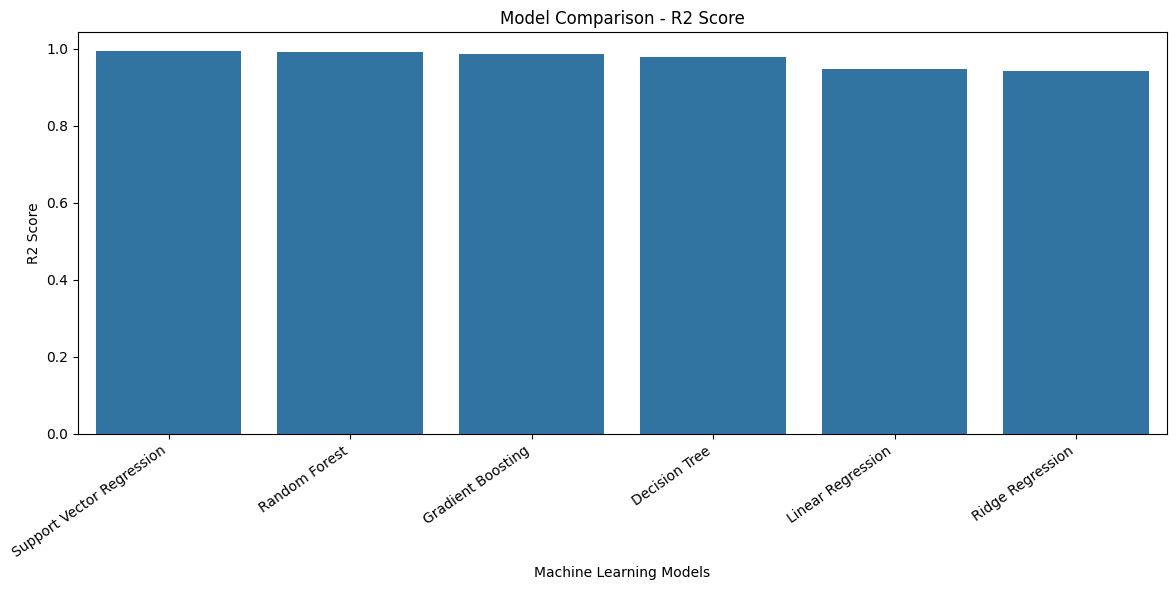

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_df,
    x='Model',
    y='R2 Score'
)

plt.title("Model Comparison - R2 Score")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")

plt.xticks(rotation=35, ha='right')
plt.tight_layout()

plt.show()

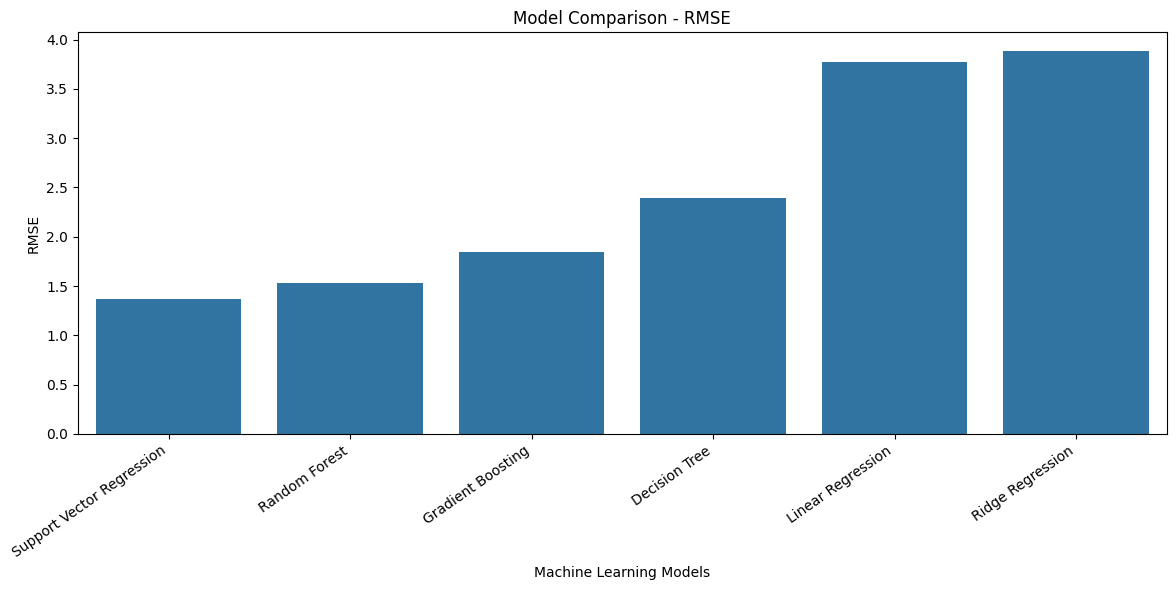

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_df,
    x='Model',
    y='RMSE'
)

plt.title("Model Comparison - RMSE")
plt.xlabel("Machine Learning Models")
plt.ylabel("RMSE")

plt.xticks(rotation=35, ha='right')
plt.tight_layout()

plt.show()

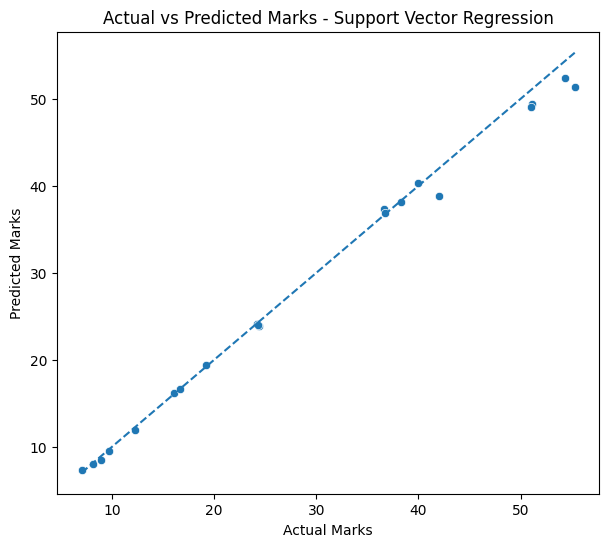

Best model: Support Vector Regression


In [ ]:
best_model_name = comparison_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

plt.figure(figsize=(7, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred
)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.title(f"Actual vs Predicted Marks - {best_model_name}")

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")

plt.show()

print("Best model:", best_model_name)

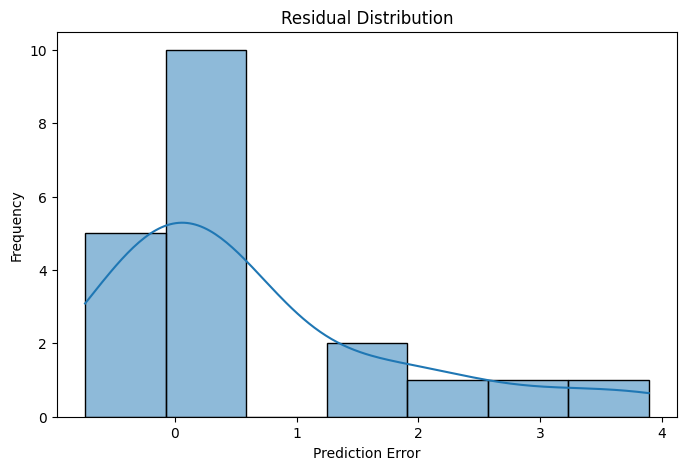

In [ ]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.title("Residual Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.show()

In [ ]:

best_model_name = comparison_df.loc[
    comparison_df['R2 Score'].idxmax(), 'Model'
]

best_model = trained_models[best_model_name]

print("BEST MACHINE LEARNING MODEL")
print("============================")
print("Algorithm:", best_model_name)

best_result = comparison_df[
    comparison_df['Model'] == best_model_name
]

display(best_result)

BEST MACHINE LEARNING MODEL
Algorithm: Support Vector Regression


,Model,MAE,MSE,RMSE,R2 Score,Adjusted R2,MAPE (%),CV R2
0,Support Vector Regression,0.831016,1.880721,1.371394,0.992847,0.992006,2.490193,0.9947
